# Weeks 7-8: full-factorial hyperparameter sweep and calibrated replication

**Pipeline:** 07a first front → **07b sweep** → calibrated Table 5 and Fig. 12

The paper reports none of its GA settings. The only outcomes it reports are a front of **18 points** found within **23,000 evaluations** (Sec. 5.2). So the settings are *calibrated*: every combination of the six NSGA-II settings below is run, and the one whose front comes closest to the paper's is kept.

Calibration runs use the paper's method, with feasibility judged from the ANN's predicted constraints (`constraints_from: ann`), so front sizes are comparable with 18. The final designs are also re-run with exact feasibility.

**Two stages**, so the run time stays manageable:

1. **Screening:** all 486 combinations × 3 seeds (1,458 runs).
2. **Confirmation:** the best 5 combinations × 10 seeds, plus a budget check on the winner.

**Selection rules, fixed before running:** (1) mean front size closest to 18; (2) then mean knee closest to the paper's (W_t 2.39 kg, C_t 2.1); (3) then highest mean hypervolume.

In [1]:
import os
import sys
import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# repo root: works whether the notebook is opened from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))     # lets us import the sandwich package even without pip install

from sandwich.config import load_problem
from sandwich.optimisation import metrics
from sandwich.optimisation.run import (load_moga_config, load_surrogate, merge_config,
                                       run_moga, run_sweep, save_result)

cfg = load_moga_config()            # settings from config/moga.yaml (its default feasibility is "exact")
surrogate = load_surrogate(cfg)     # trained ANN + Eq. 16 scalers, loaded once

# calibration uses the paper's method: feasibility from the ANN's predicted constraints, no exact filter
calib_cfg = merge_config(cfg, {"feasibility": {"constraints_from": "ann", "report_only_feasible": False}})

N_JOBS = max(1, (os.cpu_count() or 2) - 1)      # CPU cores to use (leave one free for the computer)
OUT = ROOT / "results/moga/sweep"
OUT.mkdir(parents=True, exist_ok=True)

# the paper's targets, used by the selection rules
paper = pd.DataFrame(load_problem()["pareto_designs"]["rows"])
PAPER_FRONT, PAPER_KNEE_W, PAPER_KNEE_C = 18, 2.39, 2.1
print(f"using {N_JOBS} CPU cores; calibration feasibility = {calib_cfg['feasibility']['constraints_from']}")

using 7 CPU cores; calibration feasibility = ann


## The six NSGA-II settings and the values tested

| Setting (`moga.yaml` key) | What it controls | Values tested | Why these values |
|---|---|---|---|
| Population size (`pop_size`) | How many designs are kept each generation. Also the most the final front can hold. | 50, 100, 200 | 200 is MATLAB `gamultiobj`'s default for 8 variables, 50 its default for 5 or fewer. 100 sits between. |
| Crossover probability (`crossover.prob`) | How often two parents are blended to make children. | 0.6, 0.8, 0.9 | 0.9 is the usual NSGA-II value; 0.8 is MATLAB's crossover fraction; 0.6 is a low-mixing check. |
| Crossover spread (`crossover.eta`) | How far children land from their parents. Low = big jumps, high = small steps. | 5, 15, 30 | 15 is pymoo's default, bracketed below and above. |
| Mutation rate per gene (`mutation.prob_var`) | The chance each gene gets a random nudge. | 1/16, 1/8, 1/4 | 1/8 = 1 ÷ number of genes, the standard rate; halved and doubled. |
| Mutation spread (`mutation.eta`) | How big a mutation nudge is. Low = big, high = small. | 5, 20, 50 | 20 is the usual default, bracketed below and above. |
| Selection (`selection`) | How parents are picked: the better of two random designs, or purely at random. | binary tournament, random | MATLAB uses tournament only; random checks whether selection pressure matters. |

Held fixed: **budget 23,000 evaluations** (the paper's anchor; generations = 23,000 ÷ population), the chance a child is mutated at all (0.9), and the duplicate tolerance (1e-6).

In [2]:
# every combination of the six settings: 3 x 3 x 3 x 3 x 3 x 2 = 486 combinations
GRID = {
    "pop_size":  [50, 100, 200],
    "cx_prob":   [0.6, 0.8, 0.9],
    "cx_eta":    [5, 15, 30],
    "mut_rate":  [1 / 16, 1 / 8, 1 / 4],
    "mut_eta":   [5, 20, 50],
    "selection": ["binary_tournament", "random"],
}

rows, variants = [], {}
for p, cxp, cxe, mr, me, sel in itertools.product(*GRID.values()):
    label = f"p{p}_cx{cxp}_cxe{cxe}_m{mr:.4f}_me{me}_{sel[:4]}"
    variants[label] = {"algorithm": {"pop_size": p, "selection": sel,       # the moga.yaml values this run changes
                                     "crossover": {"prob": cxp, "eta": cxe},
                                     "mutation": {"prob_var": mr, "eta": me}}}
    rows.append({"variant": label, "pop_size": p, "cx_prob": cxp, "cx_eta": cxe,
                 "mut_rate": mr, "mut_eta": me, "selection": sel,
                 "generations_approx": calib_cfg["algorithm"]["n_evaluations"] // p})
matrix = pd.DataFrame(rows).set_index("variant")
matrix.to_csv(OUT / "factorial_matrix.csv")

SEEDS_SCREEN = [1, 2, 3]
n_runs = len(variants) * len(SEEDS_SCREEN)
print(f"{len(variants)} combinations x {len(SEEDS_SCREEN)} seeds = {n_runs} runs, "
      f"about {n_runs * 2 / N_JOBS / 60:.0f} min on {N_JOBS} cores")
matrix.head()

486 combinations x 3 seeds = 1458 runs, about 7 min on 7 cores


,pop_size,cx_prob,cx_eta,mut_rate,mut_eta,selection,generations_approx
variant,,,,,,,
p50_cx0.6_cxe5_m0.0625_me5_bina,50,0.6,5,0.0625,5,binary_tournament,460
p50_cx0.6_cxe5_m0.0625_me5_rand,50,0.6,5,0.0625,5,random,460
p50_cx0.6_cxe5_m0.0625_me20_bina,50,0.6,5,0.0625,20,binary_tournament,460
p50_cx0.6_cxe5_m0.0625_me20_rand,50,0.6,5,0.0625,20,random,460
p50_cx0.6_cxe5_m0.0625_me50_bina,50,0.6,5,0.0625,50,binary_tournament,460


## Stage 1: screening

Every combination runs on 3 seeds. Each run gives one row of metrics. They're then averaged per combination and ranked by the three rules.

This is the long step, about 2 s per run divided across the CPU cores. Results are saved, so if the notebook is restarted the saved file is loaded instead of re-running.

In [3]:
screen_file = OUT / "screen_results.csv"
if screen_file.exists():
    screen = pd.read_csv(screen_file)                       # reuse a finished screening run
else:
    screen = run_sweep(variants, SEEDS_SCREEN, base_cfg=calib_cfg, surrogate=surrogate, n_jobs=N_JOBS)
    screen.to_csv(screen_file, index=False)


# averages per combination, then the three selection rules
def rank(results: pd.DataFrame) -> pd.DataFrame:
    s = results.groupby("variant").agg(
        front_mean=("cardinality", "mean"), front_sd=("cardinality", "std"),
        distinct_mean=("distinct_designs", "mean"),
        knee_W_mean=("knee_W_t", "mean"), knee_C_mean=("knee_C_t", "mean"),
        hypervolume_mean=("hypervolume", "mean"), spread_mean=("spread_delta", "mean"),
        feasible_exact_mean=("front_feasible_exact", "mean"), n_runs=("seed", "count"))
    s["off_18"] = (s.front_mean - PAPER_FRONT).abs()                            # rule 1
    s["knee_dist"] = np.hypot(s.knee_W_mean / PAPER_KNEE_W - 1,                 # rule 2
                              s.knee_C_mean / PAPER_KNEE_C - 1)
    s = s.join(matrix)
    return s.sort_values(["off_18", "knee_dist", "hypervolume_mean"], ascending=[True, True, False])  # rule 3


screen_rank = rank(screen)
screen_rank.to_csv(OUT / "screen_ranked.csv")
print(f"{len(screen)} runs; front size over all runs {screen.cardinality.min()} to {screen.cardinality.max()}; "
      f"knee W {screen.knee_W_t.min():.3f} to {screen.knee_W_t.max():.3f} kg")
screen_rank.head(10)[["front_mean", "front_sd", "distinct_mean", "knee_W_mean", "knee_C_mean",
                      "hypervolume_mean", "pop_size", "cx_prob", "cx_eta", "mut_rate", "mut_eta", "selection"]].round(3)

[Parallel(n_jobs=7)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=7)]: Done   4 tasks      | elapsed:    9.8s
[Parallel(n_jobs=7)]: Done  58 tasks      | elapsed:   50.4s
[Parallel(n_jobs=7)]: Done 148 tasks      | elapsed:  2.1min
[Parallel(n_jobs=7)]: Done 274 tasks      | elapsed:  3.7min
[Parallel(n_jobs=7)]: Done 436 tasks      | elapsed:  5.5min
[Parallel(n_jobs=7)]: Done 634 tasks      | elapsed:  8.2min
[Parallel(n_jobs=7)]: Done 868 tasks      | elapsed: 10.5min
[Parallel(n_jobs=7)]: Done 1138 tasks      | elapsed: 13.3min
[Parallel(n_jobs=7)]: Done 1444 tasks      | elapsed: 16.1min
[Parallel(n_jobs=7)]: Done 1458 out of 1458 | elapsed: 16.2min finished


1458 runs; front size over all runs 14 to 34; knee W 1.914 to 2.570 kg


,front_mean,front_sd,distinct_mean,knee_W_mean,knee_C_mean,hypervolume_mean,pop_size,cx_prob,cx_eta,mut_rate,mut_eta,selection
variant,,,,,,,,,,,,
p50_cx0.9_cxe30_m0.1250_me20_bina,18.000,2.000,14.667,2.435,2.155,2.126,50,0.9,30,0.125,20,binary_tournament
p50_cx0.9_cxe30_m0.1250_me20_rand,18.000,2.000,15.000,2.435,2.155,2.130,50,0.9,30,0.125,20,random
p50_cx0.8_cxe15_m0.0625_me20_rand,18.000,2.646,14.333,2.280,2.210,2.117,50,0.8,15,0.062,20,random
p50_cx0.9_cxe30_m0.0625_me20_rand,18.000,1.732,13.667,2.261,2.239,2.069,50,0.9,30,0.062,20,random
p100_cx0.9_cxe30_m0.0625_me50_rand,18.333,2.517,15.000,2.435,2.155,2.127,100,0.9,30,0.062,50,random
p50_cx0.8_cxe5_m0.1250_me20_rand,18.333,0.577,15.000,2.435,2.155,2.130,50,0.8,5,0.125,20,random
p50_cx0.9_cxe30_m0.0625_me20_bina,18.333,0.577,15.000,2.435,2.155,2.130,50,0.9,30,0.062,20,binary_tournament
p50_cx0.9_cxe5_m0.0625_me50_bina,18.333,2.887,14.333,2.461,2.169,2.074,50,0.9,5,0.062,50,binary_tournament
p50_cx0.8_cxe5_m0.1250_me50_bina,17.667,3.215,14.333,2.461,2.169,2.074,50,0.8,5,0.125,50,binary_tournament


## Which settings matter? (main effects)

Each panel averages every screening run at one value of one setting. A line that moves a lot means that setting changes the outcome; a flat line means it barely matters.

* **Top row:** front size, with the paper's 18 as a dashed line.
* **Bottom row:** knee weight, with the paper's 2.39 kg as a dashed line.

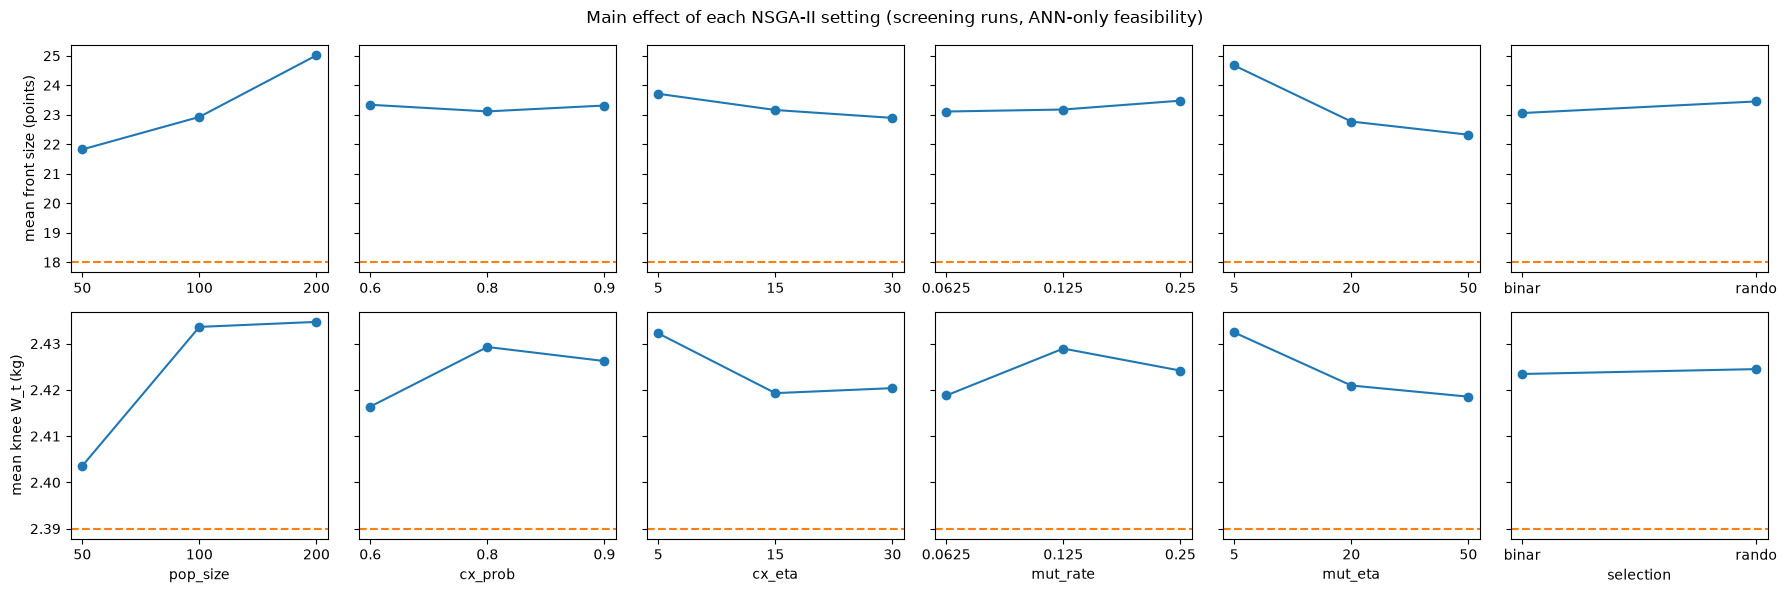

pop_size     3.19
mut_eta      2.35
cx_eta       0.82
selection    0.39
mut_rate     0.37
cx_prob      0.22
Name: front size range across levels (points), dtype: float64

In [4]:
fig, axes = plt.subplots(2, len(GRID), figsize=(3.0 * len(GRID), 6), sharey="row")
for j, name in enumerate(GRID):
    g = screen.merge(matrix[[name]], left_on="variant", right_index=True).groupby(name)
    x = [str(round(v, 4)) if isinstance(v, float) else str(v)[:5] for v in g.groups]
    axes[0, j].plot(x, g.cardinality.mean().values, "o-")
    axes[0, j].axhline(PAPER_FRONT, ls="--", c="tab:orange")
    axes[1, j].plot(x, g.knee_W_t.mean().values, "o-")
    axes[1, j].axhline(PAPER_KNEE_W, ls="--", c="tab:orange")
    axes[1, j].set_xlabel(name)
axes[0, 0].set_ylabel("mean front size (points)")
axes[1, 0].set_ylabel("mean knee W_t (kg)")
fig.suptitle("Main effect of each NSGA-II setting (screening runs, ANN-only feasibility)")
fig.tight_layout()
fig.savefig(OUT / "main_effects.png", dpi=150)
plt.show()

# how much each setting moves the mean front size between its lowest and highest level
effect = {name: np.ptp(screen.merge(matrix[[name]], left_on="variant", right_index=True)
                       .groupby(name).cardinality.mean().values) for name in GRID}
pd.Series(effect, name="front size range across levels (points)").sort_values(ascending=False).round(2)

## Stage 2: confirmation

Three seeds can rank combinations by luck. The top 5 are re-run on 10 seeds and re-ranked by the same rules. The winner is then run at half and double the budget, to check whether the front is still changing at 23,000 evaluations.

In [5]:
SEEDS_CONFIRM = list(range(1, 11))
top5 = screen_rank.index[:5]
confirm_file = OUT / "confirm_results.csv"
if confirm_file.exists():
    confirm = pd.read_csv(confirm_file)
else:
    confirm = run_sweep({v: variants[v] for v in top5}, SEEDS_CONFIRM,
                        base_cfg=calib_cfg, surrogate=surrogate, n_jobs=N_JOBS)
    confirm.to_csv(confirm_file, index=False)

confirm_rank = rank(confirm)
confirm_rank.to_csv(OUT / "confirm_ranked.csv")
WINNER = confirm_rank.index[0]
print("calibrated setting:", WINNER)

# budget check on the winner: is the front still changing at 23,000 evaluations?
budget = run_sweep({f"{n}": merge_config(variants[WINNER], {"algorithm": {"n_evaluations": n}})
                    for n in (11500, 23000, 46000)}, list(range(1, 6)),
                   base_cfg=calib_cfg, surrogate=surrogate, n_jobs=N_JOBS)
budget.to_csv(OUT / "budget_check.csv", index=False)
display(budget.groupby("variant")[["cardinality", "distinct_designs", "knee_W_t", "knee_C_t", "hypervolume"]]
        .agg(["mean", "std"]).round(3))

confirm_rank[["front_mean", "front_sd", "distinct_mean", "knee_W_mean", "knee_C_mean", "hypervolume_mean",
              "feasible_exact_mean", "pop_size", "cx_prob", "cx_eta", "mut_rate", "mut_eta", "selection"]].round(3)

[Parallel(n_jobs=7)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=7)]: Done   4 tasks      | elapsed:    6.0s
[Parallel(n_jobs=7)]: Done  48 out of  50 | elapsed:   34.6s remaining:    1.4s
[Parallel(n_jobs=7)]: Done  50 out of  50 | elapsed:   36.0s finished
[Parallel(n_jobs=7)]: Using backend LokyBackend with 7 concurrent workers.


calibrated setting: p50_cx0.9_cxe30_m0.1250_me20_rand


[Parallel(n_jobs=7)]: Done   6 out of  15 | elapsed:    4.1s remaining:    6.2s
[Parallel(n_jobs=7)]: Done  10 out of  15 | elapsed:    6.4s remaining:    3.2s
[Parallel(n_jobs=7)]: Done  15 out of  15 | elapsed:   12.0s finished


cardinality        distinct_designs        knee_W_t        knee_C_t  \
               mean    std             mean    std     mean    std     mean   
variant                                                                       
11500          17.4  1.817             14.6  0.548    2.342  0.208    2.188   
23000          18.0  2.000             15.0  0.000    2.435  0.000    2.155   
46000          19.2  2.588             15.0  0.000    2.435  0.000    2.155   

               hypervolume         
           std        mean    std  
variant                            
11500    0.074       2.122  0.012  
23000    0.000       2.130  0.000  
46000    0.000       2.130  0.000

,front_mean,front_sd,distinct_mean,knee_W_mean,knee_C_mean,hypervolume_mean,feasible_exact_mean,pop_size,cx_prob,cx_eta,mut_rate,mut_eta,selection
variant,,,,,,,,,,,,,
p50_cx0.9_cxe30_m0.1250_me20_rand,19.3,2.627,14.8,2.388,2.172,2.121,2.5,50,0.9,30,0.125,20,random
p50_cx0.9_cxe30_m0.0625_me20_rand,19.4,2.271,14.6,2.383,2.180,2.112,1.9,50,0.9,30,0.062,20,random
p50_cx0.8_cxe15_m0.0625_me20_rand,20.1,2.331,14.8,2.388,2.172,2.125,2.6,50,0.8,15,0.062,20,random
p50_cx0.9_cxe30_m0.1250_me20_bina,20.1,3.035,14.7,2.429,2.164,2.120,2.4,50,0.9,30,0.125,20,binary_tournament
p100_cx0.9_cxe30_m0.0625_me50_rand,21.7,3.713,15.0,2.435,2.155,2.129,3.5,100,0.9,30,0.062,50,random


## Calibrated replication: Fig. 12 and Table 5

The winning setting is run once more (seed 1) in both modes:

* **ANN-only feasibility:** the paper's method, compared directly with Table 5 and Fig. 12.
* **Exact feasibility:** the designs reported as truly feasible.

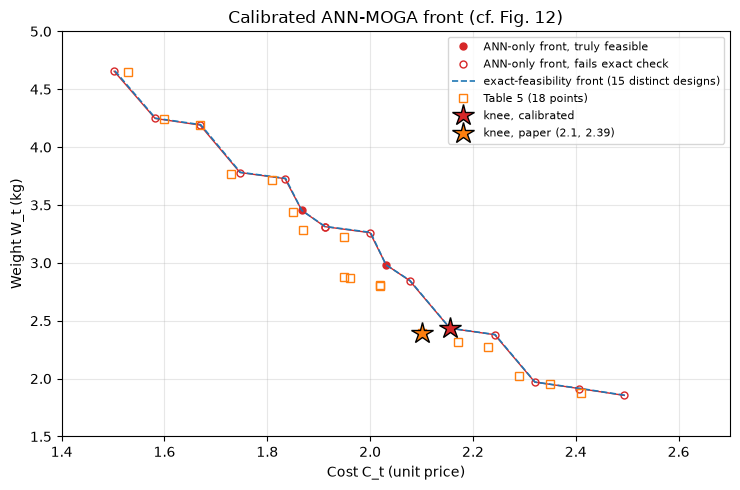

,"calibrated, ANN-only","calibrated, exact"
cardinality,16,31
distinct_designs,15,15
front_feasible_exact,2,31
knee_W_t,2.434606,2.435294
knee_C_t,2.155295,2.155362
knee_design,"{'rho_c': 29, 't_c': 18.0534906928933, 'layup'...","{'rho_c': 29, 't_c': 18.081136862188185, 'layu..."
spread_delta,0.327223,1.064974
hypervolume,2.129875,2.126548
violation_rate,0.498522,0.501435


In [6]:
winner_cfg = merge_config(calib_cfg, variants[WINNER])
cal_ann = run_moga(winner_cfg, surrogate=surrogate)
cal_exact = run_moga(merge_config(winner_cfg, {"feasibility": {"constraints_from": "exact",
                                                               "report_only_feasible": True}}),
                     surrogate=surrogate)
d_ann = save_result(cal_ann, "results/moga/calibrated_ann")
d_exact = save_result(cal_exact, "results/moga/calibrated_exact")

knee_row = paper[paper.n == cfg["targets"]["knee_row"]].iloc[0]
A, E = cal_ann.pareto, cal_exact.pareto
ok = A.feasible_exact

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(A.C_t_ann, A.W_t_ann, "-", color="tab:red", lw=1)
ax.plot(A.C_t_ann[ok], A.W_t_ann[ok], "o", ms=5, color="tab:red", label="ANN-only front, truly feasible")
ax.plot(A.C_t_ann[~ok], A.W_t_ann[~ok], "o", ms=5, mfc="none", color="tab:red", label="ANN-only front, fails exact check")
ax.plot(E.C_t_ann, E.W_t_ann, "--", color="tab:blue", lw=1.2,
        label=f"exact-feasibility front ({cal_exact.metrics['distinct_designs']} distinct designs)")
ax.plot(paper.Ct, paper.Wt, "s", ms=6, mfc="none", color="tab:orange", label="Table 5 (18 points)")
ax.plot(cal_ann.metrics["knee_C_t"], cal_ann.metrics["knee_W_t"], "*", ms=16, color="tab:red", mec="k", label="knee, calibrated")
ax.plot(knee_row.Ct, knee_row.Wt, "*", ms=16, color="tab:orange", mec="k", label="knee, paper (2.1, 2.39)")
ax.set(xlim=(1.4, 2.7), ylim=(1.5, 5.0), xlabel="Cost C_t (unit price)", ylabel="Weight W_t (kg)",
       title="Calibrated ANN-MOGA front (cf. Fig. 12)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "calibrated_front.png", dpi=150)
plt.show()

pd.concat({"calibrated, ANN-only": pd.Series(cal_ann.metrics), "calibrated, exact": pd.Series(cal_exact.metrics)},
          axis=1).loc[["cardinality", "distinct_designs", "front_feasible_exact", "knee_W_t", "knee_C_t",
                       "knee_design", "spread_delta", "hypervolume", "violation_rate"]]

In [7]:
# Table 5, row by row: each published point against the nearest point on the calibrated ANN-only front
F_paper = paper[["Wt", "Ct"]].to_numpy()
match = metrics.match_to_reference(A[["W_t_ann", "C_t_ann"]].to_numpy(), F_paper)
match.insert(0, "row", paper.n.values)
match["layup_paper"] = paper.layup.apply(lambda l: ",".join(map(str, l)))
match["layup_ours"] = A.layup.values[match.our_index]
match["rho_paper"], match["rho_ours"] = paper.rho_c.values, A.rho_c.values[match.our_index]
match["W_err_%"] = 100 * (match.W_t_ours / match.W_t_paper - 1)
match["C_err_%"] = 100 * (match.C_t_ours / match.C_t_paper - 1)
match.to_csv(OUT / "table5_comparison.csv", index=False)
print(f"weight error {match['W_err_%'].min():+.1f}% to {match['W_err_%'].max():+.1f}%, "
      f"cost error {match['C_err_%'].min():+.1f}% to {match['C_err_%'].max():+.1f}%")
match.drop(columns=["our_index"]).round(3)

weight error -2.5% to +6.2%, cost error -2.0% to +4.2%


,row,W_t_paper,C_t_paper,W_t_ours,C_t_ours,scaled_distance,layup_paper,layup_ours,rho_paper,rho_ours,W_err_%,C_err_%
0,1,1.88,2.41,1.914,2.407,0.013,"1,1,1,1,1,1","1,2,1,1,1,1",37,29,1.808,-0.118
1,2,1.95,2.35,1.970,2.320,0.034,"1,1,1,2,1,1","1,2,1,1,1,2",37,29,1.005,-1.261
2,3,2.02,2.29,1.970,2.320,0.039,"2,1,1,2,1,1","1,2,1,1,1,2",37,29,-2.495,1.326
3,4,2.27,2.23,2.379,2.242,0.042,"1,1,1,3,1,1","1,2,1,3,1,1",29,29,4.817,0.551
4,5,2.32,2.17,2.435,2.155,0.045,"1,1,1,3,1,2","1,2,1,3,1,2",29,29,4.940,-0.678
5,6,2.39,2.10,2.435,2.155,0.065,"3,1,1,2,1,2","1,2,1,3,1,2",29,29,1.866,2.633
6,7,2.80,2.02,2.846,2.077,0.067,"3,1,1,3,1,2","1,2,1,3,3,1",29,29,1.658,2.814
7,8,2.81,2.02,2.983,2.031,0.064,"2,1,1,3,1,3","1,2,1,3,3,2",29,37,6.173,0.547
8,9,2.87,1.96,2.983,2.031,0.091,"3,1,2,3,1,2","1,2,1,3,3,2",29,37,3.953,3.625
9,10,2.88,1.95,2.983,2.031,0.099,"2,1,2,3,1,3","1,2,1,3,3,2",29,37,3.592,4.156


In [8]:
# the calibrated settings, ready to copy into the algorithm block of config/moga.yaml
best = matrix.loc[WINNER]
print(yaml.safe_dump({"algorithm": {
    "pop_size": int(best.pop_size), "selection": best.selection,
    "crossover": {"prob": float(best.cx_prob), "eta": int(best.cx_eta)},
    "mutation": {"prob_var": float(best.mut_rate), "eta": int(best.mut_eta)}}}, sort_keys=False))

algorithm:
  pop_size: 50
  selection: random
  crossover:
    prob: 0.9
    eta: 30
  mutation:
    prob_var: 0.125
    eta: 20

